# WP05 · Protein dizileri ve biyokimyasal özellikler

06.11.2026 · Öğren → Ham alan → Temizleme → Doğrulama → Görselleştirme.

Protein, amino asitlerin belirli sırayla bağlandığı polimerdir. Bu analiz 20 standart amino asit politikasını kullanır; X/B/Z/J/U/O veya rakamları sessizce silmez. U/O gibi standart 20 dışı kodlar her zaman biyolojik hata değildir; bu hesap politikasında ayrı QC gerektirir. Yeni diziler yalnız seçili 62 ana DrugBank kaydından gelir. Bu notebook XML'i yeniden taramaz, Drive/UniProt sorgulamaz, eğitim veya bölme yapmaz. WP04'ün sekiz inceleme molekülü de 62 ilaç içinde korunur.

In [1]:
from pathlib import Path
import sys,json,pandas as pd,numpy as np
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'AGENTS.md').exists());sys.path.insert(0,str(ROOT/'scripts'))
from wp05_proteins import parse_sequence,features,AA,GROUPS,ProteinAnalysis,Bio
import matplotlib.pyplot as plt
import networkx as nx
import plotly.graph_objects as go
from IPython.display import display,FileLink
pd.set_option('display.max_rows',160);pd.set_option('display.max_colwidth',130)
palette={'human':'#4b8dc2','bacteria':'#e28b4d','fungus':'#9f77ad','other_eukaryote':'#888888'}
QA=ROOT/'reports/qa/WP05';FIG=ROOT/'reports/figures/WP05';FIG.mkdir(parents=True,exist_ok=True)
def read(n):return pd.read_csv(QA/n,keep_default_na=False)
summary=json.loads((QA/'coverage_summary.json').read_text(encoding='utf-8'))
registry=read('protein_registry.csv');sequences=read('protein_sequences.csv');f=read('protein_features.csv');e=read('drug_protein_edges.csv');coverage=read('drug_coverage.csv');evidence=read('relation_evidence.csv')
display(pd.DataFrame([{'Biopython':Bio.__version__,'ilaç':len(coverage),'protein':len(registry),'dizisi doğrulanmış':len(f),'UniProt_API':0}]))

,Biopython,ilaç,protein,dizisi doğrulanmış,UniProt_API
0,1.88,62,141,141,0


## 1. Amino asit, FASTA ve accession

FASTA'da `>` ile başlayan ilk satır başlıktır; izleyen satırlar dizidir. Başlıktaki protein adı amino asit hesabına katılmaz. UniProt accession P/Q/O baş harflerinden oluşan bir kalite puanı değildir. Accession biçimi ve XML `polypeptide/@id`–UniProtKB dış kimliği uyumu kontrol edilir; bağımsız UniProt kaydının güncelliği doğrulandı denmez.

Motilin receptor örneğinde ham başlık, temiz dizi başlangıcı ve uzunluk farkını doğrudan karşılaştıralım. Amino asit frekansı, kalıntı sayısının temiz dizi uzunluğuna oranıdır (0–1).

In [2]:
raw_records=json.loads((QA/'xml_protein_records.json').read_text(encoding='utf-8'))
example=next(r for d in raw_records for r in d['relations'] if r.get('polypeptide_id')=='O43193')
parsed=parse_sequence(example['raw_sequence'])
display(pd.DataFrame([{'accession':example['polypeptide_id'],'protein':example['protein_name'],'organism':example['organism'],'raw_prefix':example['raw_sequence'][:170],'header':parsed['header'],'clean_prefix':parsed['sequence'][:100],'raw_length':parsed['raw_length'],'clean_length':parsed['length'],'QC':parsed['status']}]))
display(read('amino_acid_dictionary.csv'))
display(f[f.accession.eq('O43193')][['accession','length_aa',*['AAC_'+x for x in AA]]])

,accession,protein,organism,raw_prefix,header,clean_prefix,raw_length,clean_length,QC
0,O43193,Motilin receptor,Humans,>lcl|BSEQ0006793|Motilin receptor\nMGSPWNGSDGPEGAREPPWPALPPCDERRCSPFPLGALVPVTAVCLCLFVVGVSGNVVTV\nMLIGRYRDMRTTTNLYLGSMAVSDLLILL...,>lcl|BSEQ0006793|Motilin receptor,MGSPWNGSDGPEGAREPPWPALPPCDERRCSPFPLGALVPVTAVCLCLFVVGVSGNVVTVMLIGRYRDMRTTTNLYLGSMAVSDLLILLGLPFDLYRLWR,452,412,valid


,AA,three_letter,Turkce_ad,group
0,A,Ala,Alanin,nonpolar_nonaromatic
1,C,Cys,Sistein,polar_uncharged
2,D,Asp,Aspartat,acidic
3,E,Glu,Glutamat,acidic
4,F,Phe,Fenilalanin,aromatic
5,G,Gly,Glisin,nonpolar_nonaromatic
6,H,His,Histidin,basic
7,I,Ile,İzolösin,nonpolar_nonaromatic
8,K,Lys,Lizin,basic
9,L,Leu,Lösin,nonpolar_nonaromatic


,accession,length_aa,AAC_A,AAC_C,AAC_D,AAC_E,AAC_F,AAC_G,AAC_H,AAC_I,AAC_K,AAC_L,AAC_M,AAC_N,AAC_P,AAC_Q,AAC_R,AAC_S,AAC_T,AAC_V,AAC_W,AAC_Y
9,O43193,412,0.089806,0.024272,0.024272,0.033981,0.041262,0.080097,0.009709,0.041262,0.012136,0.140777,0.021845,0.021845,0.082524,0.012136,0.09466,0.07767,0.050971,0.082524,0.021845,0.036408


**Yorum:** Başlık ve satır sonları ayrıldı; doğal harflerden rastgele “dizi” üretmek için regex filtresi kullanılmadı. 478 polipeptit kanıt satırının tamamı tek FASTA başlığı sonrası 20-AA dizisi verdi. Aynı accession'ın birden fazla ilaçta görünmesi diziyi yeni protein diye çoğaltmaz; 141 accession'da dizi/taksonomi çakışması yok. Bu 141 kimlik 140 farklı temiz dizi içeriyor; P0A3M5/P0A3M6 aynı diziye sahip fakat kaynak kimlikleri birleştirilmedi. Aynı dizi kimlik eşitliğini tek başına kanıtlamaz.

## 2. Eski hataları gerçek kayıtlarla görmek

Eski `sequence` alanı bu XML'de polipeptit amino asit dizisi değil; doğru yol `.../polypeptide/amino-acid-sequence`. Eski CSV 70 başlığı satır sonunu kaybederek diziye birleştirmiş. Başlık içindeki standart AA harflerini seçmek başlığı temizlemez; sahte kalıntı ekler. `FASTA başlığı + dizi` satır sınırı kaybolmuşsa başlığı tahmin ederek ayırmıyoruz; yeni XML dizisiyle karşılaştırıyoruz.

,accession,starts_fasta_header,strict_parse_status,new_xml_sequence_available,extra_residues_if_old_regex,prefix_sample
0,P10613,True,fasta_missing_sequence_boundary,False,,>lcl|BSEQ0010022|Lanosterol 14-alpha demethylaseMAIVETVIDGINYFLSLSVTQQISILLGVPFVYNLVWQYLYSLRKDRAPLVF
1,P0C0X2,True,fasta_missing_sequence_boundary,False,,>lcl|BSEQ0011514|Inactive dihydropteroate synthase 2MQSMLCGRPVAADRQLIMAIVNRTPDSFYDRGATFSDEAARAAAHRAV
2,P0C0X1,True,fasta_missing_sequence_boundary,False,,>lcl|BSEQ0011512|Dihydropteroate synthaseMSLAPVQVIGVLNVTDNSFSDGGRYLDPDDAVQHGLAMVAEGAAIVDVGGESTRPGAIR
3,O15554,True,fasta_missing_sequence_boundary,False,,>lcl|BSEQ0016086|Intermediate conductance calcium-activated potassium channel protein 4MGGDLVLGLGALR
4,P25025,True,fasta_missing_sequence_boundary,False,,>lcl|BSEQ0053319|C-X-C chemokine receptor type 2MEDFNMESDSFEDFWKGEDLSNYSYSSTLPPFLLDAAPCEPESLEINKYFVV
5,O75469,True,fasta_missing_sequence_boundary,False,,>lcl|BSEQ0001903|Nuclear receptor subfamily 1 group I member 2MEVRPKESWNHADFVHCEDTESVPGKPSVNADEEVGGP
6,Q8TDS4,True,fasta_missing_sequence_boundary,False,,>lcl|BSEQ0010442|Hydroxycarboxylic acid receptor 2MNRHHLQDHFLEIDKKNCCVFRDDFIVKVLPPVLGLEFIFGLLGNGLALW
7,P0AC13,True,fasta_missing_sequence_boundary,True,27.0,>lcl|BSEQ0001602|Dihydropteroate synthaseMKLFAQGTSLDLSHPHVMGILNVTPDSFSDGGTHNSLIDAVKHANLMINAGATIIDVGG
8,Q8XJ01,True,fasta_missing_sequence_boundary,True,29.0,>lcl|BSEQ0016139|Penicillin-binding protein 1AMTERKREHKDRKQNKNSPKNQSKVTKFLKWFFIGILLLGITAVTVVGIYVLSII
9,P02918,True,fasta_missing_sequence_boundary,True,29.0,>lcl|BSEQ0001173|Penicillin-binding protein 1AMKFVKYFLILAVCCILLGAGSIYGLYRYIEPQLPDVATLKDVRLQIPMQIYSAD


,eski_baslıklı,eski_prefix_skor_formülü_uyumlu,XML_ile_karşılaştırılabilen_eski_dizi,XML_eski_sequence_etiketi
0,70,70,51,0


,AA,old_groups,old_membership_count,new_group
0,A,hydrophobic,1,nonpolar_nonaromatic
1,C,,0,polar_uncharged
2,D,acidic,1,acidic
3,E,acidic,1,acidic
4,F,hydrophobic|aromatic,2,aromatic
5,G,,0,nonpolar_nonaromatic
6,H,basic,1,basic
7,I,hydrophobic,1,nonpolar_nonaromatic
8,K,basic,1,basic
9,L,hydrophobic,1,nonpolar_nonaromatic


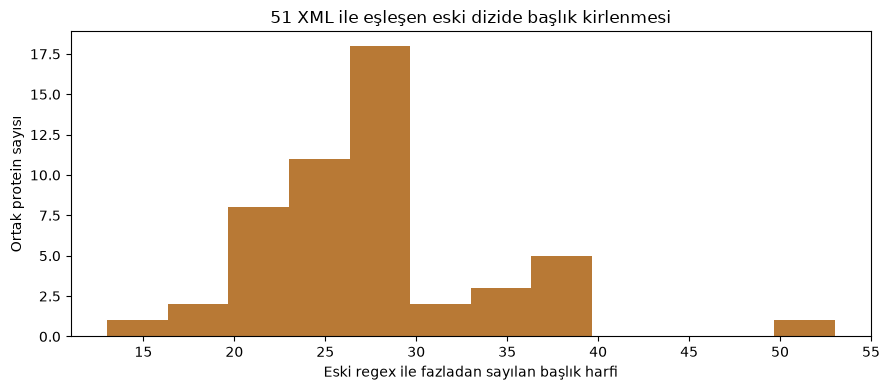

In [3]:
oldseq=read('legacy_sequence_audit.csv');oldid=read('legacy_identity_organism_audit.csv')
display(oldseq[['accession','starts_fasta_header','strict_parse_status','new_xml_sequence_available','extra_residues_if_old_regex','prefix_sample']].head(12))
display(pd.DataFrame([{'eski_baslıklı':int(oldseq.starts_fasta_header.sum()),'eski_prefix_skor_formülü_uyumlu':int(oldid.prefix_formula_matches.sum()),'XML_ile_karşılaştırılabilen_eski_dizi':int(oldseq.new_xml_sequence_available.sum()),'XML_eski_sequence_etiketi':summary['old_sequence_tag_present']}]))
display(read('amino_acid_group_audit.csv'))
fig,ax=plt.subplots(figsize=(9,4));values=pd.to_numeric(oldseq.extra_residues_if_old_regex,errors='coerce').dropna();ax.hist(values,bins=12,color='#b87935');ax.set(xlabel='Eski regex ile fazladan sayılan başlık harfi',ylabel='Ortak protein sayısı',title='51 XML ile eşleşen eski dizide başlık kirlenmesi');plt.tight_layout();plt.savefig(FIG/'01_legacy_header_contamination.png',dpi=160);plt.show()

**Yorum:** 51 ortak accession'ın eski metni yeni temiz XML dizisiyle tam olarak bitiyor; başlık harfleri 13–53 ek kalıntı üretebiliyor. Bu örnek doğrudan kaynak karşılaştırmasıdır; eski özelliklerin tamamının hangi kod revizyonuyla üretildiği ispatlanmış değildir. Eski F hem hidrofobik hem aromatik grupta, C/G hiçbir grupta; yeni açık bölümleme bunları düzeltir. Eski P/Q/O skoru 70/70 formülle uyumlu ve yeni özelliklerde yok.

## 3. Hedef, enzim, transporter ve carrier farklı ilişkiler

`target`: kaynakta ilaç hedef ilişkisi; tümü ana antibakteriyel mekanizma değildir. `enzyme`: metabolizma/etkileşim enzimi olabilir; hedefin yerine geçmez. `transporter`: ilaç alımı/atılımıyla ilişkili taşıyıcı; `carrier`: kaynakta taşıma/bağlanma rolü. İsim biyolojik işlevi çağrıştırsa da XML rolü silinmez. Örneğin Vancomycin için kaynakta carrier bölümündeki fare H1 reseptörü ayrıca yorum gerektirir; onu insan antibakteriyel hedefi diye yeniden etiketlemiyoruz.

,role,unique_drug_protein_role_edges,drugs,unique_proteins,no_polypeptide_records
0,target,241,55,89,27
1,enzyme,78,38,30,0
2,transporter,135,43,28,0
3,carrier,22,19,4,0


,drug_id,role,relation_name,accession,organism,actions,known_action,relation_qc
0,DB00199,target,23S ribosomal RNA,,,inhibitor,yes,nonprotein_rRNA
1,DB00199,target,Motilin receptor,O43193,Humans,agonist,no,polypeptide
2,DB00199,target,Voltage-gated inwardly rectifying potassium channel KCNH2,Q12809,Humans,inhibitor,no,polypeptide
3,DB00199,enzyme,Cytochrome P450 3A5,P20815,Humans,substrate|inhibitor,unknown,polypeptide
4,DB00199,enzyme,Cytochrome P450 3A4,P08684,Humans,substrate|inhibitor,no,polypeptide
5,DB00199,enzyme,Cytochrome P450 3A7,P24462,Humans,substrate|inhibitor,no,polypeptide
6,DB00199,transporter,Solute carrier organic anion transporter family member 1B3,Q9NPD5,Humans,substrate|inhibitor,unknown,polypeptide
7,DB00199,transporter,Bile salt export pump,O95342,Humans,substrate|inhibitor,no,polypeptide
8,DB00199,transporter,ATP-dependent translocase ABCB1,P08183,Humans,substrate|inhibitor,no,polypeptide
9,DB00199,transporter,Solute carrier organic anion transporter family member 1B1,Q9Y6L6,Humans,substrate|inhibitor,no,polypeptide


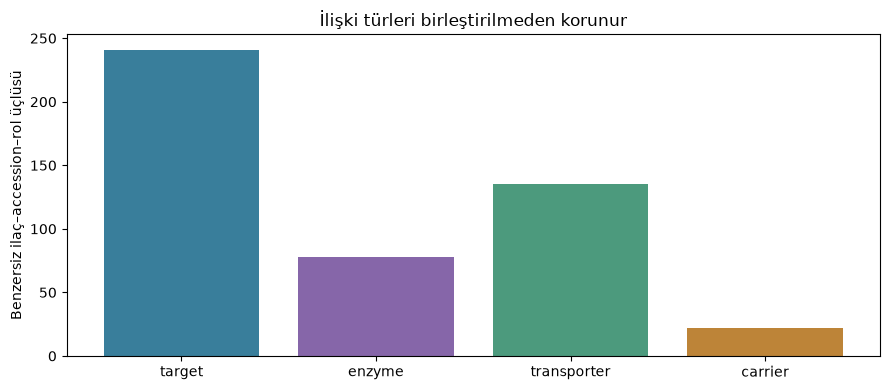

In [4]:
display(read('role_summary.csv'))
display(evidence[evidence.drug_id.isin(['DB00199','DB00254','DB00512','DB00601'])][['drug_id','role','relation_name','accession','organism','actions','known_action','relation_qc']])
roles=read('role_summary.csv');fig,ax=plt.subplots(figsize=(9,4));ax.bar(roles.role,roles.unique_drug_protein_role_edges,color=['#397e9b','#8666a9','#4c9a7d','#bd8438']);ax.set(ylabel='Benzersiz ilaç–accession–rol üçlüsü',title='İlişki türleri birleştirilmeden korunur');plt.tight_layout();plt.savefig(FIG/'02_relation_roles.png',dpi=160);plt.show()

**Yorum:** 476 benzersiz tipli kenar var. Rol unutulunca 457 ilaç–protein çifti kalır; fark, aynı çiftin birden çok biyolojik rol taşıyabilmesidir. `target` kapsamı 55, tüm roller kapsamı 60; 60 hedefli ilaç demek doğru olmaz. 478 kaynak polipeptit satırı da kenar sayısı değildir; kaynak tekrarları izleriyle korunup kenarlar tekilleştirildi.

## 4. Protein olmayan ve kimliği/dizisi bulunmayan hedefler

rRNA bir protein dizisi değildir; DNA, membran ve peptidoglikan alt yapıları için protein özelliği uydurulmaz. “Peptidoglycan transpeptidase” ise enzim adıdır; polipeptit kaydı yok diye hücre duvarı maddesi sayılmaz. 30S ribosomal protein adında da protein var; belirli accession/dizi bu kayıtta eksik.

In [5]:
display(read('nonprotein_or_unresolved_targets.csv')[['drug_id','drug_name','relation_name','relation_qc','source_path']])
display(read('priority_seven.csv'))

,drug_id,drug_name,relation_name,relation_qc,source_path
0,DB00199,Erythromycin,23S ribosomal RNA,nonprotein_rRNA,drug/targets/target[1]
1,DB00207,Azithromycin,23S ribosomal RNA,nonprotein_rRNA,drug/targets/target[1]
2,DB00254,Doxycycline,30S ribosomal protein,protein_named_missing_polypeptide,drug/targets/target[1]
3,DB00512,Vancomycin,D-Ala-D-Ala moiety of NAM/NAG peptide subunits of peptidoglycan,nonprotein_cell_envelope_or_peptide,drug/targets/target[1]
4,DB00535,Cefdinir,Peptidoglycan transpeptidase,protein_named_missing_polypeptide,drug/targets/target[4]
5,DB00560,Tigecycline,16S ribosomal RNA,nonprotein_rRNA,drug/targets/target[1]
6,DB00595,Oxytetracycline,16S ribosomal RNA,nonprotein_rRNA,drug/targets/target[3]
7,DB00601,Linezolid,23S ribosomal RNA,nonprotein_rRNA,drug/targets/target[1]
8,DB00684,Tobramycin,16S ribosomal RNA,nonprotein_rRNA,drug/targets/target[1]
9,DB00684,Tobramycin,23S ribosomal RNA,nonprotein_rRNA,drug/targets/target[2]


,id,name,target_proteins,all_role_proteins,feature_proteins,enzyme_proteins,transporter_proteins,carrier_proteins,no_polypeptide_records,nonprotein_target_names,modal_status,retained_in_cohort
0,DB00254,Doxycycline,0,4,4,1,2,1,1,30S ribosomal protein,protein_features_available,True
1,DB00512,Vancomycin,0,4,4,0,0,4,1,D-Ala-D-Ala moiety of NAM/NAG peptide subunits of peptidoglycan,protein_features_available,True
2,DB00601,Linezolid,0,5,5,2,2,1,1,23S ribosomal RNA,protein_features_available,True
3,DB00684,Tobramycin,0,0,0,0,0,0,4,16S ribosomal RNA | 23S ribosomal RNA | Bacterial outer membrane | Cytoplasmic membrane,no_validated_protein_features,True
4,DB00911,Tinidazole,0,2,2,1,1,0,1,DNA,protein_features_available,True
5,DB00976,Telithromycin,0,3,3,1,2,0,1,23S ribosomal RNA,protein_features_available,True
6,DB06799,Methenamine,0,0,0,0,0,0,0,,no_validated_protein_features,True


**Yorum:** Doxycycline, Vancomycin, Linezolid, Tinidazole ve Telithromycin'de diğer roller üzerinden doğrulanmış protein dizileri var; antibakteriyel protein hedefi eksikliği böylece giderilmiş sayılmaz. Tobramycin'de RNA/membran hedefleri var; Methenamine'de bu dört bölümde ilişki yok. İkisi de kapsamda kalır; “biyolojik hedef yok” veya “yan etki yok” çıkarımı yapılmaz.

## 5. Protein uzunluğu, molekül ağırlığı ve AAC

Uzunluk temiz amino asit sayısıdır. MW, Biopython 1.88'de ortalama serbest amino asit kütleleri toplamından her peptit bağı için su çıkarılarak hesaplanır; burada tek doğrusal, modifikasyonsuz dizi varsayılır. Birim Da (kDa = Da/1000); deneysel olgun protein kütlesi, multimer veya glikozillenmiş kütle değildir. AAC frekansları yuvarlanmadan hesaplanır, toplamı 1'dir.

,accession,protein_name,organism,sequence_validated,length_aa,molecular_weight_Da
103,P98164,Low-density lipoprotein receptor-related protein 2,Humans,True,4655,521952.7643
105,Q02880,DNA topoisomerase 2-beta,Humans,True,1626,183264.9577
128,Q92887,ATP-binding cassette sub-family C member 2,Humans,True,1545,174205.2374
58,P11388,DNA topoisomerase 2-alpha,Humans,True,1531,174383.0282
81,P33527,Multidrug resistance-associated protein 1,Humans,True,1531,171589.1277
7,O15439,ATP-binding cassette sub-family C member 4,Humans,True,1325,149524.9285
12,O95342,Bile salt export pump,Humans,True,1321,146405.4712
30,P08183,ATP-dependent translocase ABCB1,Humans,True,1280,141476.7717
110,Q2M3G0,ATP-binding cassette sub-family B member 5,Humans,True,1257,138639.1656
93,P52647,Probable pyruvate-flavodoxin oxidoreductase,Escherichia coli (strain K12),True,1174,128822.9354


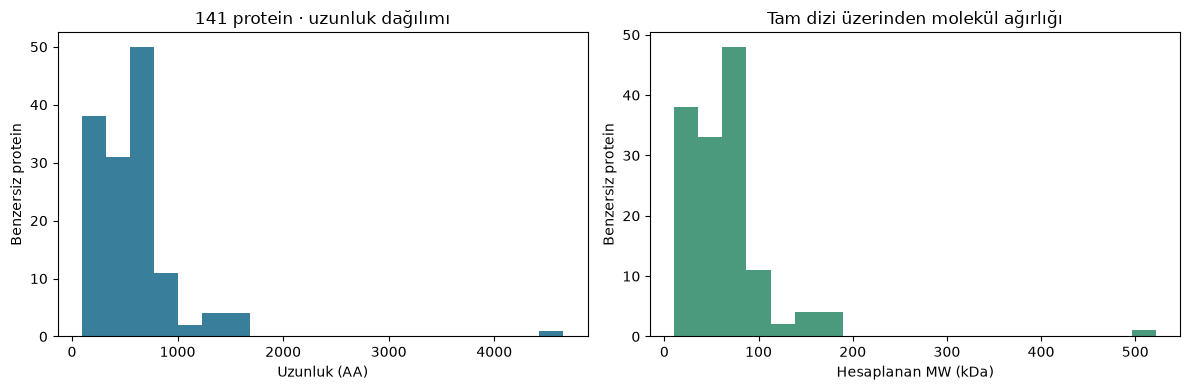

,AA,protein_eşit_ağırlıklı_ortalama,kalıntı_ağırlıklı_oran
0,A,0.074219,0.072279
1,C,0.013298,0.015570
2,D,0.050176,0.052277
3,E,0.060217,0.059862
4,F,0.042668,0.042831
5,G,0.070964,0.071156
6,H,0.019553,0.018698
7,I,0.059354,0.060792
8,K,0.060757,0.058848
9,L,0.100105,0.098659


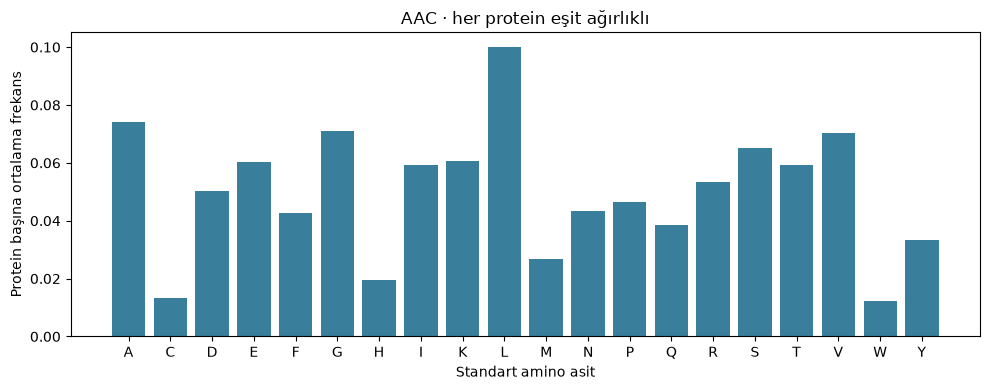

In [6]:
display(registry[['accession','protein_name','organism','sequence_validated']].merge(f[['accession','length_aa','molecular_weight_Da']],on='accession').sort_values('length_aa',ascending=False).head(12))
fig,axes=plt.subplots(1,2,figsize=(12,4));axes[0].hist(f.length_aa,bins=20,color='#397e9b');axes[0].set(xlabel='Uzunluk (AA)',ylabel='Benzersiz protein',title='141 protein · uzunluk dağılımı')
axes[1].hist(f.molecular_weight_Da/1000,bins=20,color='#4c9a7d');axes[1].set(xlabel='Hesaplanan MW (kDa)',ylabel='Benzersiz protein',title='Tam dizi üzerinden molekül ağırlığı');plt.tight_layout();plt.savefig(FIG/'03_length_and_mass.png',dpi=160);plt.show()
aac=f[['AAC_'+a for a in AA]];display(pd.DataFrame({'AA':list(AA),'protein_eşit_ağırlıklı_ortalama':aac.mean().values,'kalıntı_ağırlıklı_oran':np.average(aac,axis=0,weights=f.length_aa)}))
fig,ax=plt.subplots(figsize=(10,4));ax.bar(list(AA),aac.mean().values,color='#397e9b');ax.set(xlabel='Standart amino asit',ylabel='Protein başına ortalama frekans',title='AAC · her protein eşit ağırlıklı');plt.tight_layout();plt.savefig(FIG/'04_amino_acid_composition.png',dpi=160);plt.show()

**Yorum:** Uzunluklar 92–4.655 AA. Çok uzun kayıtlar otomatik kesilmedi; 2D/3D yapı üretilmiyor. AAC grafiğinde her protein eşit ağırlıklı; tüm kalıntılar bir havuzda sayılsaydı uzun proteinler daha ağır basardı. Bu iki istatistik aynı değildir. Protein büyüklüğü tek başına ilaç yan etki riski göstermez.

## 6. pI, aromatiklik, GRAVY ve pH'ya bağlı yük

Teorik pI, Bjellqvist pKa tabanlı yük modelinde net yükün yaklaşık sıfır olduğu pH'dır. İki uç ve iyonlaşabilen yan zincirler dikkate alınır; protein katlanması/PTM/ortam ayrıntıları bilinmez. Bisection 0–14 aralığında yürütülür; sonuç deneysel pI değildir. Aromatiklik `(F+W+Y)/L`; GRAVY Kyte–Doolittle kalıntı hidropati puanlarının ortalaması, boyutsuz. Net yük pH 7,0'da temel yük e cinsinden kuramsal toplamdır; pozitif gruptaki histidin sayısını sabit +1 yük saymak doğru değildir.

,accession,isoelectric_point,aromaticity_fraction,gravy_kyte_doolittle,net_charge_pH7
0,A0A0H2XJ39,9.248837,0.073806,-0.603039,17.240397
1,B2ZTR6,9.174068,0.111421,-0.457103,8.119382
2,B4YQT9,4.696583,0.057692,-0.280128,-9.896473
3,C3T8E2,9.629673,0.096280,0.760175,10.922861
4,D6R448,6.822880,0.105263,-0.697895,-0.113157
5,O15244,8.678890,0.120721,0.313874,7.118080
6,O15245,6.402950,0.106498,0.451805,-1.997792
7,O15439,8.410526,0.097358,0.078717,8.945758
8,O25608,8.170788,0.085714,-0.197143,2.083704
9,O43193,9.966770,0.099515,0.290534,19.780226


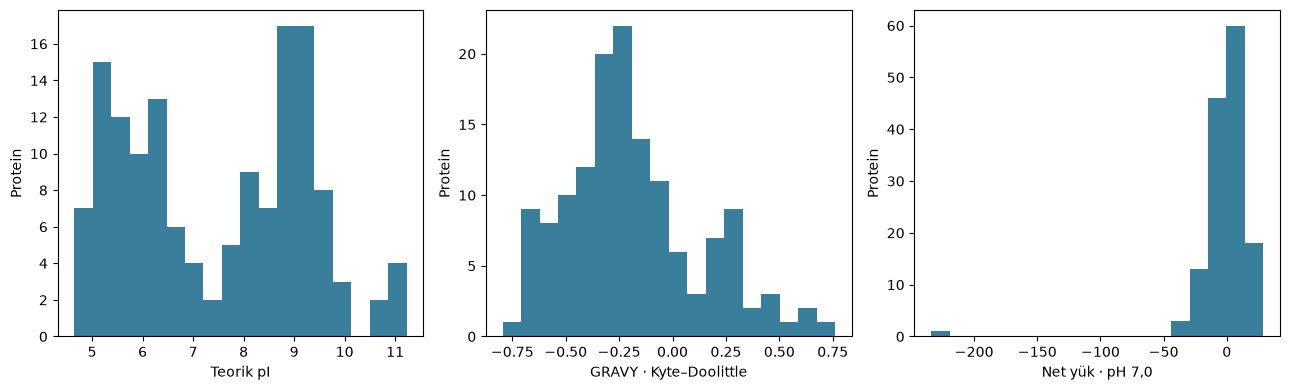

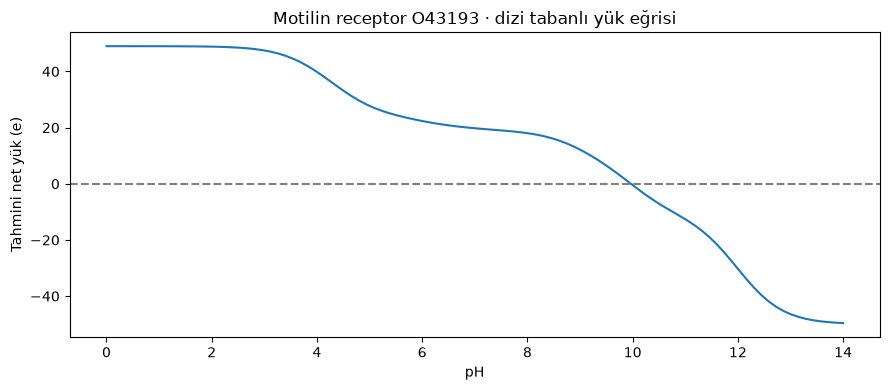

In [7]:
display(f[['accession','isoelectric_point','aromaticity_fraction','gravy_kyte_doolittle','net_charge_pH7']].head(12))
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,col,title in zip(axes,['isoelectric_point','gravy_kyte_doolittle','net_charge_pH7'],['Teorik pI','GRAVY · Kyte–Doolittle','Net yük · pH 7,0']):
    ax.hist(f[col],bins=18,color='#397e9b');ax.set(xlabel=title,ylabel='Protein')
plt.tight_layout();plt.savefig(FIG/'05_biochemical_properties.png',dpi=160);plt.show()
seq=sequences.set_index('accession').loc['O43193','sequence'];analysis=ProteinAnalysis(seq);ph=np.linspace(0,14,100)
fig,ax=plt.subplots(figsize=(9,4));ax.plot(ph,[analysis.charge_at_pH(float(p)) for p in ph]);ax.axhline(0,color='gray',ls='--');ax.set(xlabel='pH',ylabel='Tahmini net yük (e)',title='Motilin receptor O43193 · dizi tabanlı yük eğrisi');plt.tight_layout();plt.savefig(FIG/'06_charge_curve.png',dpi=160);plt.show()

**Yorum:** Aynı proteinin yükü pH ile değişir; pozitif/negatif amino asit oranı gerçek net yükle aynı ölçü değildir. GRAVY bütün dizinin ortalaması olduğundan yerel transmembran parçalarını tek başına kanıtlamaz. Bu değerler ölçülmüş işlev veya klinik risk değildir.

## 7. Yeni, açık amino asit grupları ve grup dipeptitleri

Eski 5 grubun yerine 20 amino asidi tam ve çakışmasız kapsayan açık bir bölümleme tanımlandı: nonpolar/nonaromatik AGILMPV, aromatik FWY, polar yüksüz CNQST, bazik HKR, asidik DE. Bu tezdeki operasyonel bölümlemedir; tek evrensel biyokimyasal sınıflama değildir. Y aromatik gruba önceliklidir; histidinin pH bağımlılığı pI/yük hesabında ayrıca ele alınır.

Grup DC: ardışık, yönlü `i→i+1` grup çiftlerinin sayısı / `(L−1)`. Atlanan kalıntı yok. Tek amino asitli dizide dipeptit tanımsız ve null olur; veri yerine sıfır doldurulmaz. Bu örneklemde bütün diziler en az 92 AA.

,grup,AA
0,nonpolar_nonaromatic,AGILMPV
1,aromatic,FWY
2,polar_uncharged,CNQST
3,basic,HKR
4,acidic,DE


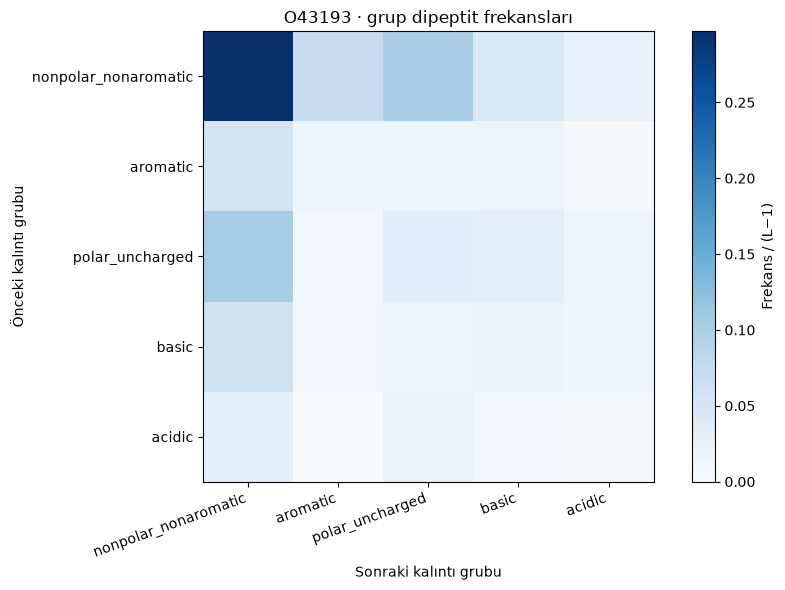

,AAC_toplam,grup_DC_toplam_min
0,1.0,1.0


In [8]:
display(pd.DataFrame([{'grup':g,'AA':members} for g,members in GROUPS.items()]))
groups=list(GROUPS);row=f.set_index('accession').loc['O43193'];matrix=np.array([[row[f'DC_{a}__{b}'] for b in groups] for a in groups])
fig,ax=plt.subplots(figsize=(9,6));im=ax.imshow(matrix,cmap='Blues');ax.set_xticks(range(5),groups,rotation=20,ha='right');ax.set_yticks(range(5),groups);ax.set(xlabel='Sonraki kalıntı grubu',ylabel='Önceki kalıntı grubu',title='O43193 · grup dipeptit frekansları');fig.colorbar(im,ax=ax,label='Frekans / (L−1)');plt.tight_layout();plt.savefig(FIG/'07_group_dipeptides.png',dpi=160);plt.show()
display(pd.DataFrame([{'AAC_toplam':f[['AAC_'+a for a in AA]].sum(axis=1).min(),'grup_DC_toplam_min':f[[c for c in f if c.startswith('DC_')]].sum(axis=1).min()}]))

**Yorum:** F artık iki kez sayılmıyor, C ve G kapsamda. 25 hücre yönlü komşuluk frekansıdır; `A→B` ile `B→A` aynı hücre değil. Bu dizisel özet 3D protein teması veya PPI kenarı değildir; grup tanımı kaynak/sürümle dondurulmalıdır.

## 8. Organizma: insan ≠ tüm diğerleri bakteri

XML'deki polipeptit organizması ve taksonomi ID'si aynen korunur. İnsan 9606 veya açık Humans/Homo sapiens adı; bakteriler yalnız açık gözden geçirilmiş organizma adlarıyla sınıflandı. Yeast mantar, Mouse ve Plasmodium diğer ökaryot olarak ayrıldı. Kaynak isimlerinin 29 ayrı ad/taksonomi grubu var; bunlar 29 ayrı tür demek değildir. 28 farklı dolu taksonomi ID'si ve bir ID'siz Pseudomonas adı var; tür/strain birleştirmesi yapılmadı.

,organism,taxid,group,unique_proteins
0,Acinetobacter baumannii,470,bacteria,1
1,Bacillus cereus,1396,bacteria,1
2,Bacillus licheniformis,1402,bacteria,1
3,Bacillus subtilis (strain 168),224308,bacteria,4
4,Clostridium perfringens (strain 13 / Type A),195102,bacteria,1
5,Escherichia coli,562,bacteria,6
6,Escherichia coli (strain K12),83333,bacteria,23
7,Haemophilus influenzae,727,bacteria,1
8,Haemophilus influenzae (strain ATCC 51907 / DSM 11121 / KW20 / Rd),71421,bacteria,4
9,Helicobacter pylori,210,bacteria,1


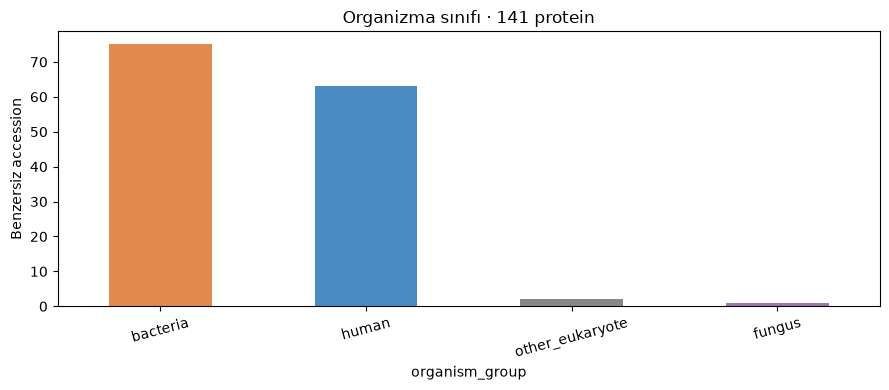

organism_group,bacteria,fungus,human,other_eukaryote
role,,,,
carrier,0,0,21,1
enzyme,9,0,69,0
target,197,1,42,1
transporter,0,0,135,0


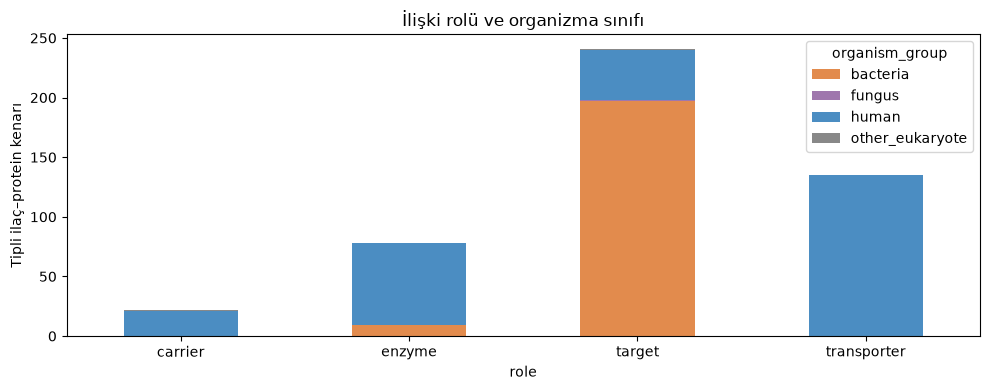

In [9]:
display(read('organism_summary.csv'))
counts=registry.organism_group.value_counts();fig,ax=plt.subplots(figsize=(9,4));counts.plot.bar(ax=ax,color=[palette[g] for g in counts.index]);ax.set(ylabel='Benzersiz accession',title='Organizma sınıfı · 141 protein');plt.xticks(rotation=15);plt.tight_layout();plt.savefig(FIG/'08_organism_groups.png',dpi=160);plt.show()
rg=e.merge(registry[['accession','organism_group']],on='accession');cross=pd.crosstab(rg.role,rg.organism_group);display(cross)
cross.plot.bar(stacked=True,figsize=(10,4),color=[palette[g] for g in cross.columns]);plt.ylabel('Tipli ilaç–protein kenarı');plt.title('İlişki rolü ve organizma sınıfı');plt.xticks(rotation=0);plt.tight_layout();plt.savefig(FIG/'09_role_organism.png',dpi=160);plt.show()

**Yorum:** 75 bakteri, 63 insan, 1 mantar, 2 diğer ökaryot accession var. Bu yan ilişki kayıtlarının tümünün antibakteriyel mekanizmayı veya insan yan etki mekanizmasını anlattığı iddia edilmez. Bu organizmalar yalnız izinli DrugBank içinde görüldü; yeni türler için STRING veya başka veri indirilmedi.

## 9. 62 ilacın protein modalitesi

Target-only ve tüm rol kapsamını yan yana gösterelim. Eksik modaliteyi bir ilacın biyolojik hedefi veya yan etkisi yokmuş gibi kodlamayız. İleride kimya tabanlı alternatif, bağımsız eksiklik maskesi veya rol bazlı ablation değerlendirilebilir; bugün model kararı/tensör yok.

,id,name,target_proteins,all_role_proteins,feature_proteins,enzyme_proteins,transporter_proteins,carrier_proteins,no_polypeptide_records,nonprotein_target_names,modal_status,retained_in_cohort
13,DB00479,Amikacin,1,1,1,0,0,0,0,,protein_features_available,True
42,DB01060,Amoxicillin,1,7,7,2,3,1,0,,protein_features_available,True
8,DB00415,Ampicillin,7,10,10,0,4,1,0,,protein_features_available,True
1,DB00207,Azithromycin,1,4,4,1,2,0,1,23S ribosomal RNA,protein_features_available,True
40,DB01053,Benzylpenicillin,8,18,18,1,11,1,0,,protein_features_available,True
21,DB00578,Carbenicillin,8,10,10,1,1,0,0,,protein_features_available,True
52,DB01327,Cefazolin,8,14,14,1,4,1,0,,protein_features_available,True
17,DB00535,Cefdinir,3,8,8,0,5,0,1,Peptidoglycan transpeptidase,protein_features_available,True
55,DB01413,Cefepime,7,10,10,0,3,0,0,,protein_features_available,True
25,DB00671,Cefixime,7,11,11,0,4,0,0,,protein_features_available,True


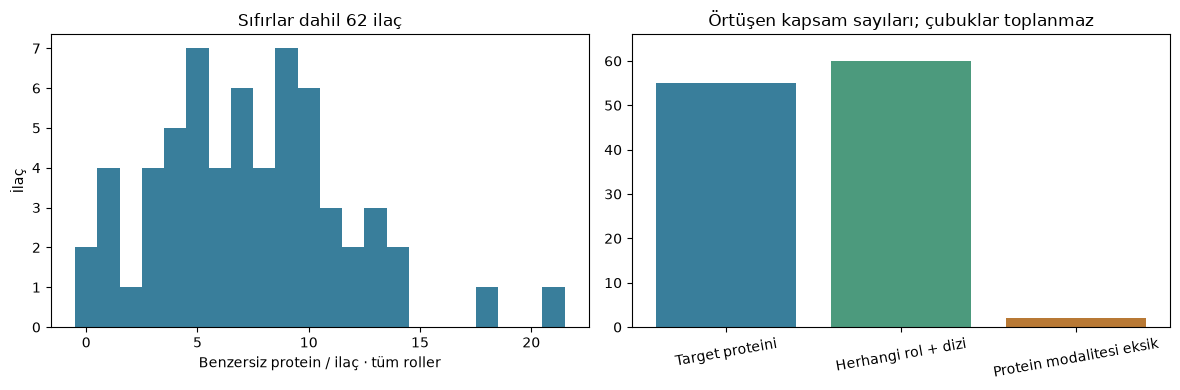

In [10]:
display(coverage.sort_values('name'))
fig,axes=plt.subplots(1,2,figsize=(12,4));bins=np.arange(0,max(coverage.all_role_proteins)+2)-.5
axes[0].hist(coverage.all_role_proteins,bins=bins,color='#397e9b');axes[0].set(xlabel='Benzersiz protein / ilaç · tüm roller',ylabel='İlaç',title='Sıfırlar dahil 62 ilaç')
axes[1].bar(['Target proteini','Herhangi rol + dizi','Protein modalitesi eksik'],[55,60,2],color=['#397e9b','#4c9a7d','#b87935']);axes[1].set_ylim(0,66);axes[1].tick_params(axis='x',rotation=10);axes[1].set_title('Örtüşen kapsam sayıları; çubuklar toplanmaz');plt.tight_layout();plt.savefig(FIG/'10_drug_coverage.png',dpi=160);plt.show()

**Yorum:** Tüm rol kapsamında eksik iki ilaç Tobramycin ve Methenamine. Protein özelliği olan ilaçları filtreleyip diğerlerini dosyadan silmedik. WP04'te incelemede kalan sekiz molekül de listede duruyor; protein varlığı moleküler QC kararını değiştirmez.

## 10. İki parçalı ilaç–protein grafı ve önemli düğümler

Tam QA grafı 62 ilaç + 141 protein içerir; kenar, tekil kaynak ilaç–accession çiftidir. Çoklu roller kenar açıklamasında korunur. Aşağıdaki küçük alt graf, seçili sekiz ilaç ile yalnız gösterim için en bağlantılı 16 proteini alır; tam ağa göre kapsam/merkezilik kaybı olabilir. İzole ilaçlar çizimde tutulur. Derece merkezilik göstergesidir, risk skoru değildir.

,accession,protein,organism_group,degree_drugs,degree_fraction_62
18,P02768,Albumin,human,20,0.322581
112,Q4U2R8,Solute carrier family 22 member 6,human,20,0.322581
32,P08684,Cytochrome P450 3A4,human,18,0.290323
88,P46059,Solute carrier family 15 member 1,human,14,0.225806
25,P05177,Cytochrome P450 1A2,human,12,0.193548
108,Q16348,Solute carrier family 15 member 2,human,12,0.193548
126,Q8TCC7,Organic anion transporter 3,human,12,0.193548
19,P02918,Penicillin-binding protein 1A,bacteria,11,0.177419
20,P02919,Penicillin-binding protein 1B,bacteria,11,0.177419
30,P08183,ATP-dependent translocase ABCB1,human,10,0.161290


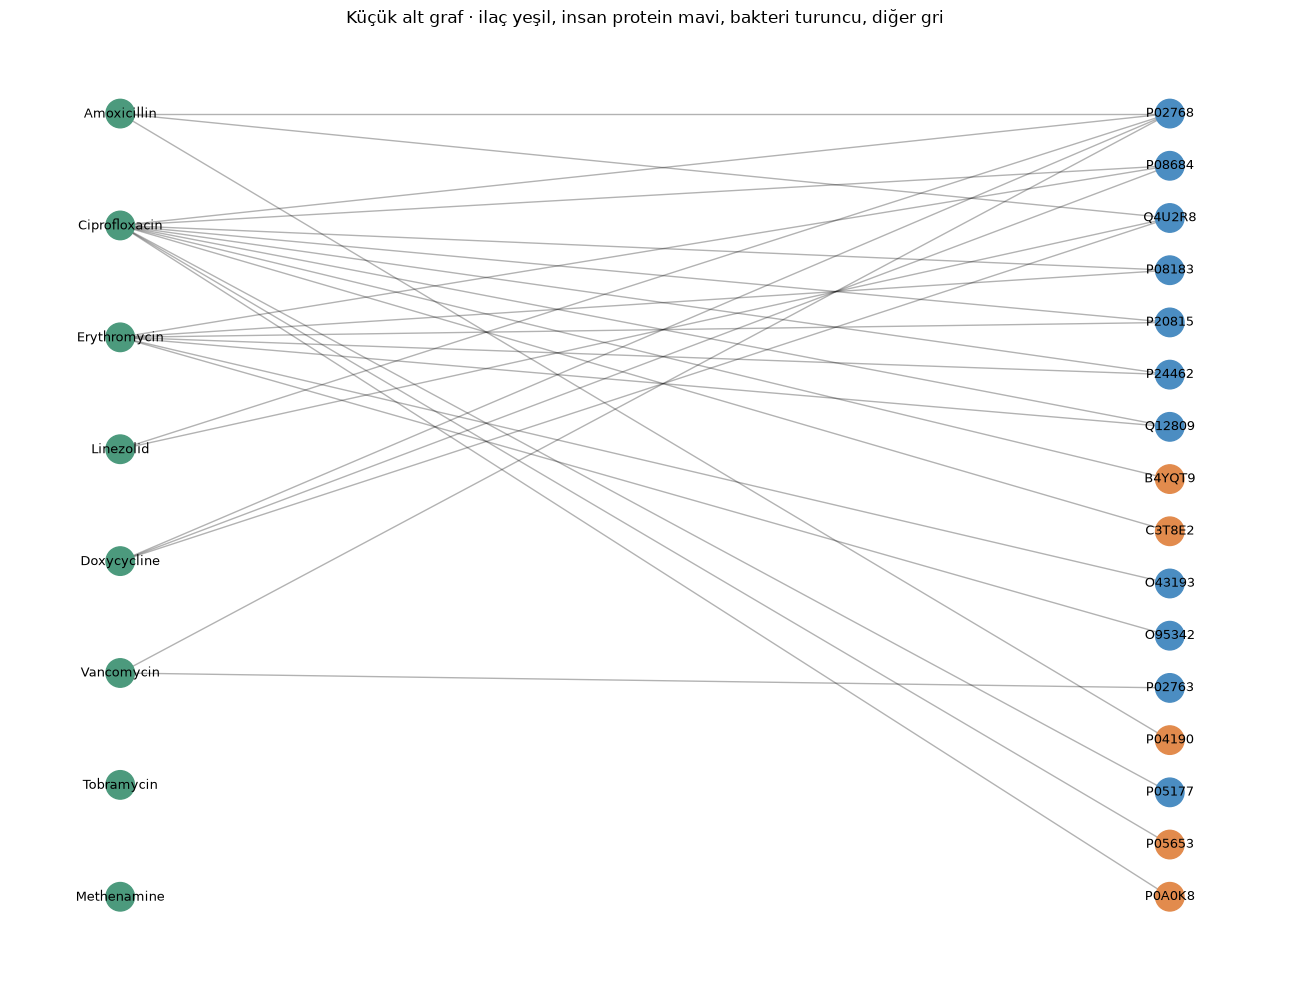

,drug_nodes,protein_nodes,untyped_edges,components,isolates,display_subgraph_nodes,display_subgraph_edges
0,62,141,457,4,"[D:DB00684, D:DB06799]",24,28


C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\figures\WP05\drug_protein_interactive.html

In [11]:
G=nx.Graph()
G.add_nodes_from('D:'+i for i in coverage.id);G.add_nodes_from('P:'+i for i in registry.accession)
for r in e.itertuples():G.add_edge('D:'+r.drug_id,'P:'+r.accession)
metrics=[]
for r in registry.itertuples():metrics.append({'accession':r.accession,'protein':r.protein_name,'organism_group':r.organism_group,'degree_drugs':G.degree('P:'+r.accession),'degree_fraction_62':G.degree('P:'+r.accession)/62})
metrics=pd.DataFrame(metrics).sort_values(['degree_drugs','accession'],ascending=[False,True]);metrics.to_csv(QA/'protein_graph_metrics.csv',index=False,encoding='utf-8-sig');display(metrics.head(12))
chosen=['DB01060','DB00537','DB00199','DB00601','DB00254','DB00512','DB00684','DB06799'];near=e[e.drug_id.isin(chosen)].groupby('accession').drug_id.nunique();picked=sorted(near.index,key=lambda a:(-near[a],a))[:16]
H=G.subgraph(['D:'+i for i in chosen]+['P:'+i for i in picked]).copy()
pos={'D:'+a:(0,-i/(len(chosen)-1)) for i,a in enumerate(chosen)}|{'P:'+a:(1,-i/(len(picked)-1)) for i,a in enumerate(picked)}
names=coverage.set_index('id').name.to_dict();groups=registry.set_index('accession').organism_group.to_dict()
palette={'human':'#4b8dc2','bacteria':'#e28b4d','fungus':'#9f77ad','other_eukaryote':'#888888'}
colors=['#4c9a7d' if n.startswith('D:') else palette.get(groups[n[2:]],'#999999') for n in H]
labels={n:names[n[2:]] if n.startswith('D:') else n[2:] for n in H}
fig,ax=plt.subplots(figsize=(13,10));nx.draw_networkx_edges(H,pos,ax=ax,alpha=.3);nx.draw_networkx_nodes(H,pos,ax=ax,node_color=colors,node_size=420);nx.draw_networkx_labels(H,pos,labels=labels,font_size=9,ax=ax);ax.set_title('Küçük alt graf · ilaç yeşil, insan protein mavi, bakteri turuncu, diğer gri');ax.axis('off');plt.tight_layout();plt.savefig(FIG/'11_bipartite_subgraph.png',dpi=170);plt.show()
graph_summary={'drug_nodes':62,'protein_nodes':141,'untyped_edges':G.number_of_edges(),'components':nx.number_connected_components(G),'isolates':list(nx.isolates(G)),'display_subgraph_nodes':H.number_of_nodes(),'display_subgraph_edges':H.number_of_edges()};(QA/'graph_summary.json').write_text(json.dumps(graph_summary,ensure_ascii=False,indent=2),encoding='utf-8');display(pd.DataFrame([graph_summary]))
traces=[]
for a,b in H.edges:
    traces.append(go.Scatter(x=[pos[a][0],pos[b][0]],y=[pos[a][1],pos[b][1]],mode='lines',line=dict(color='#bbbbbb',width=1),hoverinfo='skip',showlegend=False))
hover=[]
for n in H:
    if n.startswith('D:'):hover.append(n[2:]+' · '+names[n[2:]])
    else:
        row=registry.set_index('accession').loc[n[2:]];hover.append(n[2:]+' · '+row.protein_name+' · '+row.organism)
traces.append(go.Scatter(x=[pos[n][0] for n in H],y=[pos[n][1] for n in H],mode='markers+text',text=[labels[n] for n in H],textposition='middle right',marker=dict(size=13,color=colors),hovertext=hover,hoverinfo='text',showlegend=False))
fig=go.Figure(traces);fig.update_layout(title='WP05 kaynak alt grafı · eğitim grafı değil',height=850,xaxis=dict(visible=False),yaxis=dict(visible=False),margin=dict(l=160,r=180));fig.write_html(FIG/'drug_protein_interactive.html',include_plotlyjs=True,full_html=True);display(FileLink(str(FIG/'drug_protein_interactive.html')))

**Yorum:** Tam graf derecesi birçok ilaca bağlanan paylaşılan proteinleri ortaya çıkarır. En yüksek dereceli düğümler çoğunlukla metabolizma/taşıma/bağlanma rollerinde olabilir; ana antibakteriyel hedef oldukları sonucu çıkmaz. Her düğüm/kenarın kaynak izi ilişki tablosuna gider. 476 tipli kenarı 457 çiftte gösteren bu grafik, rol bilgisini özellik/öğrenme girdisine çevirmedi. HTML çevrimdışı Plotly içerir; canlı tarayıcı etkileşimi test edilmedi.

## Kapanış: desteklenen düğüm/kenarlar ve sınırlar

DrugBank ana ilaç düğümü, yerel accession/dizi protein düğümü, dört farklı ilaç–protein rolü gerçek veriye dayanıyor. rRNA/DNA/membran/hedef yapıları ayrı kaynak hedef varlıkları olarak tutulabilir; bugün protein düğümü/özelliği üretilmedi. Önceki SIDER PT ilişkileri ayrı hedef etiket katmanıdır. PPI, atom grafı, eğitim tensörü, negatif örnek veya ilaç ayrımı bu WP'de oluşturulmadı. Özellik tablosu kimlik dışında yalnız diziden hesaplanan sayıları içerir; organizma/skor/merkezilik/PT sayısı X'e eklenmez.

Kimlik ve diziler yalnız yerel XML içinde doğrulandı. Bağımsız UniProt güncellik/dizi/izoform sorgusu yok; eksik hedefe isim benzerliğiyle accession atanmadı. WP05 sonunda kullanıcı onayı beklenir.

Yöntem belgeleri: [Biopython ProtParam](https://biopython.org/docs/latest/api/Bio.SeqUtils.ProtParam.html), [pI/yük yöntemi](https://biopython.org/docs/latest/api/Bio.SeqUtils.IsoelectricPoint.html), [UniProt accession biçimi](https://www.uniprot.org/help/accession_numbers).